In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
import sys

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from plotting_utils import save_fig

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
RAW_DIR = os.path.join(PROJECT_ROOT, config["paths"]["raw_dir"])

data_path = os.path.join(RAW_DIR, config["raw_files"]["arab5_data"])
desc_path = os.path.join(RAW_DIR, config["raw_files"]["arab5_descriptions"])

df = pd.read_excel(data_path)
descriptions = pd.read_excel(desc_path, sheet_name="Descriptions")
categories = pd.read_excel(desc_path, sheet_name="Variables categories")

print("Shape:", df.shape)

Shape: (3569, 48)


In [2]:
df.head()

,f_id,part1_country,Locality_first,part1_current_preg_first,Anxietyrec1,Anxietyrec2,Anxietyrec3,Anxietyrec4,Anxietyrec5,Anxietyrec6,Anxietyrec7,DepressionRec1,DepressionRec2,DepressionRec3,DepressionRec4,DepressionRec5,DepressionRec6,DepressionRec7,DepressionRec8,Depressionec9,GAD_7_Anxiety_score_Cat_first,PHQ_9_Depression_Score_first,AnxietyCat_first,DepressionCat_first,WomenAge,MariageAge,NumberofPregnancy,NumberofAbortions,EducationLevel,Work,CovidDiagL1,CovidDiagL2,Health_Prob,StressduringCovid,FamilyProblems,FinancialProblem,SocialProblem,PsychologicalProb,WorkStress,FamilyIncome1,SleepingAfter,BMI_Pregnancy,BMI_Postpartum,Food_Group_Adher_During_CAT,Physical_activity_During_Cat,Smoker_During_preg_Cat,Anxeity_Rec,Depression_Rec1
0,2,2,1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3,4.0,2.0,2,1,0,0,0,0,0,0,0,0,0,2,2,2.0,2.0,NaN,NaN,NaN,1,1
1,3,2,1,1,NaN,NaN,3.0,2.0,3.0,3.0,1.0,2.0,1.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0,6.0,3.0,1.0,1,2,2.0,0.0,2,1,0,0,0,1,1,1,0,0,0,1,1,0.0,NaN,0.0,0.0,NaN,3,1
2,4,2,1,1,NaN,NaN,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,1.0,1.0,1,2,3.0,0.0,2,2,0,0,0,1,0,0,0,0,0,2,2,2.0,NaN,0.0,1.0,0.0,1,1
3,5,4,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3,2.0,0.0,2,1,0,0,0,0,0,0,0,0,0,1,2,0.0,0.0,NaN,NaN,0.0,1,1
4,6,4,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,2.0,0.0,2,1,0,0,0,0,0,0,0,0,0,2,3,0.0,NaN,0.0,1.0,0.0,1,1


In [3]:
descriptions

,Variable Information,Unnamed: 1
0,Variable,Label
1,f_id,File Number
2,part1_country,The country of residence
3,Locality_first,Place of residance
4,part1_current_preg_first,Are you currently pregnant?
5,Anxietyrec1,"Feeling nervous, anxious, or on edge"
6,Anxietyrec2,Not being able to stop or control worrying
7,Anxietyrec3,Worrying too much about different things
8,Anxietyrec4,Trouble relaxing
9,Anxietyrec5,Being so restless that it is hard to sit still


In [4]:
df.dtypes

f_id                               int64
part1_country                      int64
Locality_first                     int64
part1_current_preg_first           int64
Anxietyrec1                      float64
Anxietyrec2                      float64
Anxietyrec3                      float64
Anxietyrec4                      float64
Anxietyrec5                      float64
Anxietyrec6                      float64
Anxietyrec7                      float64
DepressionRec1                   float64
DepressionRec2                   float64
DepressionRec3                   float64
DepressionRec4                   float64
DepressionRec5                   float64
DepressionRec6                   float64
DepressionRec7                   float64
DepressionRec8                   float64
Depressionec9                    float64
GAD_7_Anxiety_score_Cat_first    float64
PHQ_9_Depression_Score_first     float64
AnxietyCat_first                 float64
DepressionCat_first              float64
WomenAge        

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
print(missing)

Anxietyrec2                      2474
Anxietyrec1                      2474
BMI_Postpartum                   2219
Food_Group_Adher_During_CAT      2199
DepressionRec2                   1990
DepressionRec8                   1989
DepressionRec3                   1988
DepressionRec7                   1987
Depressionec9                    1987
DepressionRec1                   1985
DepressionRec6                   1984
DepressionRec4                   1984
DepressionRec5                   1983
Anxietyrec6                      1982
Anxietyrec5                      1976
Anxietyrec3                      1975
Anxietyrec7                      1975
Anxietyrec4                      1974
PHQ_9_Depression_Score_first     1968
DepressionCat_first              1968
Smoker_During_preg_Cat           1860
GAD_7_Anxiety_score_Cat_first    1855
AnxietyCat_first                 1855
Physical_activity_During_Cat     1474
BMI_Pregnancy                     537
NumberofAbortions                   4
NumberofPreg

country_label
Palestine       1000
Saudi Arabia     967
NaN              848
Jordan           754
Name: count, dtype: int64
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\sample_by_country.png


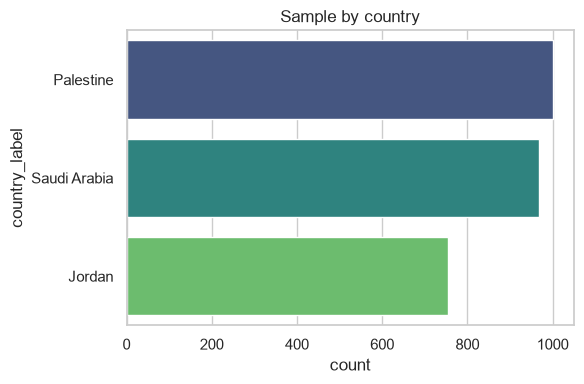

In [6]:
country_map = {1: "Jordan", 2: "Palestine", 3: "Lebanon", 4: "Saudi Arabia", 5: "Bahrain"}
df["country_label"] = df["part1_country"].map(country_map)
print(df["country_label"].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, y="country_label", order=df["country_label"].value_counts().index,
              hue="country_label", palette="viridis", legend=False, ax=ax)
ax.set_title("Sample by country")
plt.tight_layout()
save_fig(fig, "sample_by_country.png", PROJECT_ROOT, dataset="arab5")
plt.show()

Depression_Rec1_label
Minimal/Mild                2846
Moderate                     413
Moderately Severe/Severe     310
Name: count, dtype: int64
Depression_Rec1_label
Minimal/Mild                79.74
Moderate                    11.57
Moderately Severe/Severe     8.69
Name: proportion, dtype: float64 %
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\depression_class_balance.png


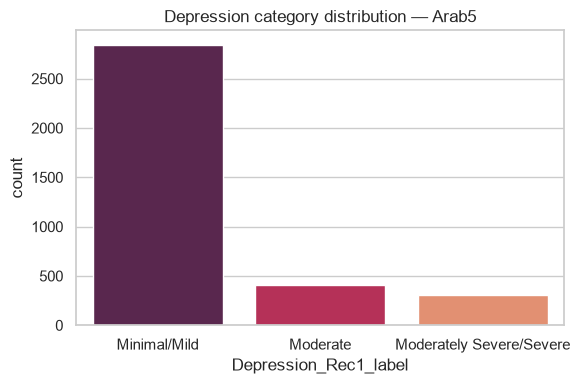

In [7]:
dep_map = {1: "Minimal/Mild", 2: "Moderate", 3: "Moderately Severe/Severe"}
df["Depression_Rec1_label"] = df["Depression_Rec1"].map(dep_map)
print(df["Depression_Rec1_label"].value_counts(dropna=False))
print(df["Depression_Rec1_label"].value_counts(normalize=True).round(4) * 100, "%")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Depression_Rec1_label", hue="Depression_Rec1_label",
              order=dep_map.values(), palette="rocket", legend=False, ax=ax)
ax.set_title("Depression category distribution — Arab5")
plt.tight_layout()
save_fig(fig, "depression_class_balance.png", PROJECT_ROOT, dataset="arab5")
plt.show()

Anxeity_Rec_label
Minimal/Mild                2492
Moderate                     801
Moderately Severe/Severe     276
Name: count, dtype: int64
Anxeity_Rec_label
Minimal/Mild                69.82
Moderate                    22.44
Moderately Severe/Severe     7.73
Name: proportion, dtype: float64 %
Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\anxiety_class_balance.png


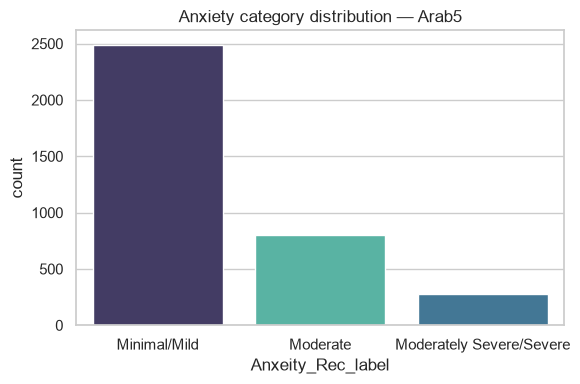

In [8]:
anx_map = {1: "Minimal/Mild", 2: "Moderate", 3: "Moderately Severe/Severe"}
df["Anxeity_Rec_label"] = df["Anxeity_Rec"].map(anx_map)
print(df["Anxeity_Rec_label"].value_counts(dropna=False))
print(df["Anxeity_Rec_label"].value_counts(normalize=True).round(4) * 100, "%")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="Anxeity_Rec_label", hue="Anxeity_Rec_label",
              order=anx_map.values(), palette="mako", legend=False, ax=ax)
ax.set_title("Anxiety category distribution — Arab5")
plt.tight_layout()
save_fig(fig, "anxiety_class_balance.png", PROJECT_ROOT, dataset="arab5")
plt.show()

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\score_distributions.png


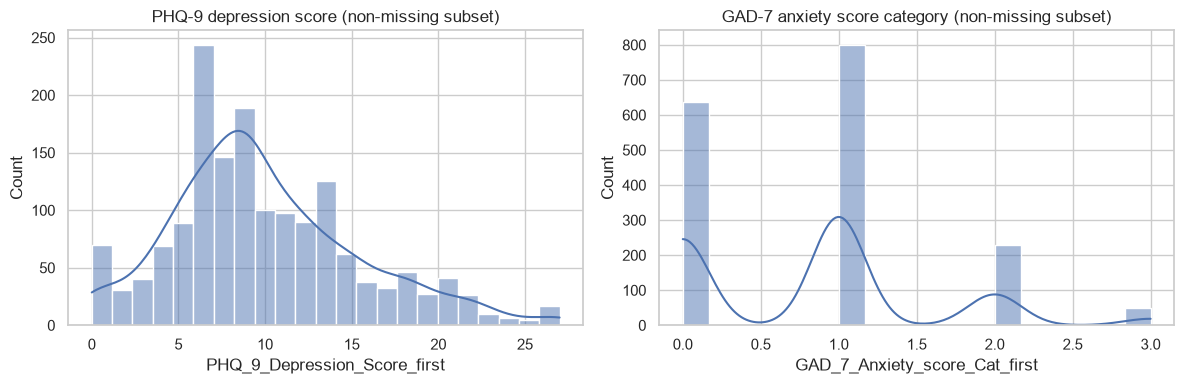

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["PHQ_9_Depression_Score_first"].dropna(), kde=True, ax=axes[0])
axes[0].set_title("PHQ-9 depression score (non-missing subset)")
sns.histplot(df["GAD_7_Anxiety_score_Cat_first"].dropna(), kde=True, ax=axes[1])
axes[1].set_title("GAD-7 anxiety score category (non-missing subset)")
plt.tight_layout()
save_fig(fig, "score_distributions.png", PROJECT_ROOT, dataset="arab5")
plt.show()

In [10]:
sdoh_cols = ["country_label", "Locality_first", "WomenAge", "MariageAge", "NumberofPregnancy",
             "NumberofAbortions", "EducationLevel", "Work", "CovidDiagL1", "CovidDiagL2",
             "Health_Prob", "StressduringCovid", "FamilyProblems", "FinancialProblem",
             "SocialProblem", "PsychologicalProb", "WorkStress", "FamilyIncome1", "SleepingAfter"]

for col in sdoh_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- country_label ---
country_label
Palestine       1000
Saudi Arabia     967
NaN              848
Jordan           754
Name: count, dtype: int64

--- Locality_first ---
Locality_first
1    2455
2    1114
Name: count, dtype: int64

--- WomenAge ---
WomenAge
1    3048
2     521
Name: count, dtype: int64

--- MariageAge ---
MariageAge
2     2739
1      604
3      225
11       1
Name: count, dtype: int64

--- NumberofPregnancy ---
NumberofPregnancy
1.0     1249
2.0      972
4.0      725
3.0      620
NaN        2
11.0       1
Name: count, dtype: int64

--- NumberofAbortions ---
NumberofAbortions
0.0    2620
1.0     632
2.0     313
NaN       4
Name: count, dtype: int64

--- EducationLevel ---
EducationLevel
2    2858
1     711
Name: count, dtype: int64

--- Work ---
Work
2    2188
1    1381
Name: count, dtype: int64

--- CovidDiagL1 ---
CovidDiagL1
0    3322
1     247
Name: count, dtype: int64

--- CovidDiagL2 ---
CovidDiagL2
0    2931
1     638
Name: count, dtype: int64

--- Health_Prob --

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\sdoh_distributions.png


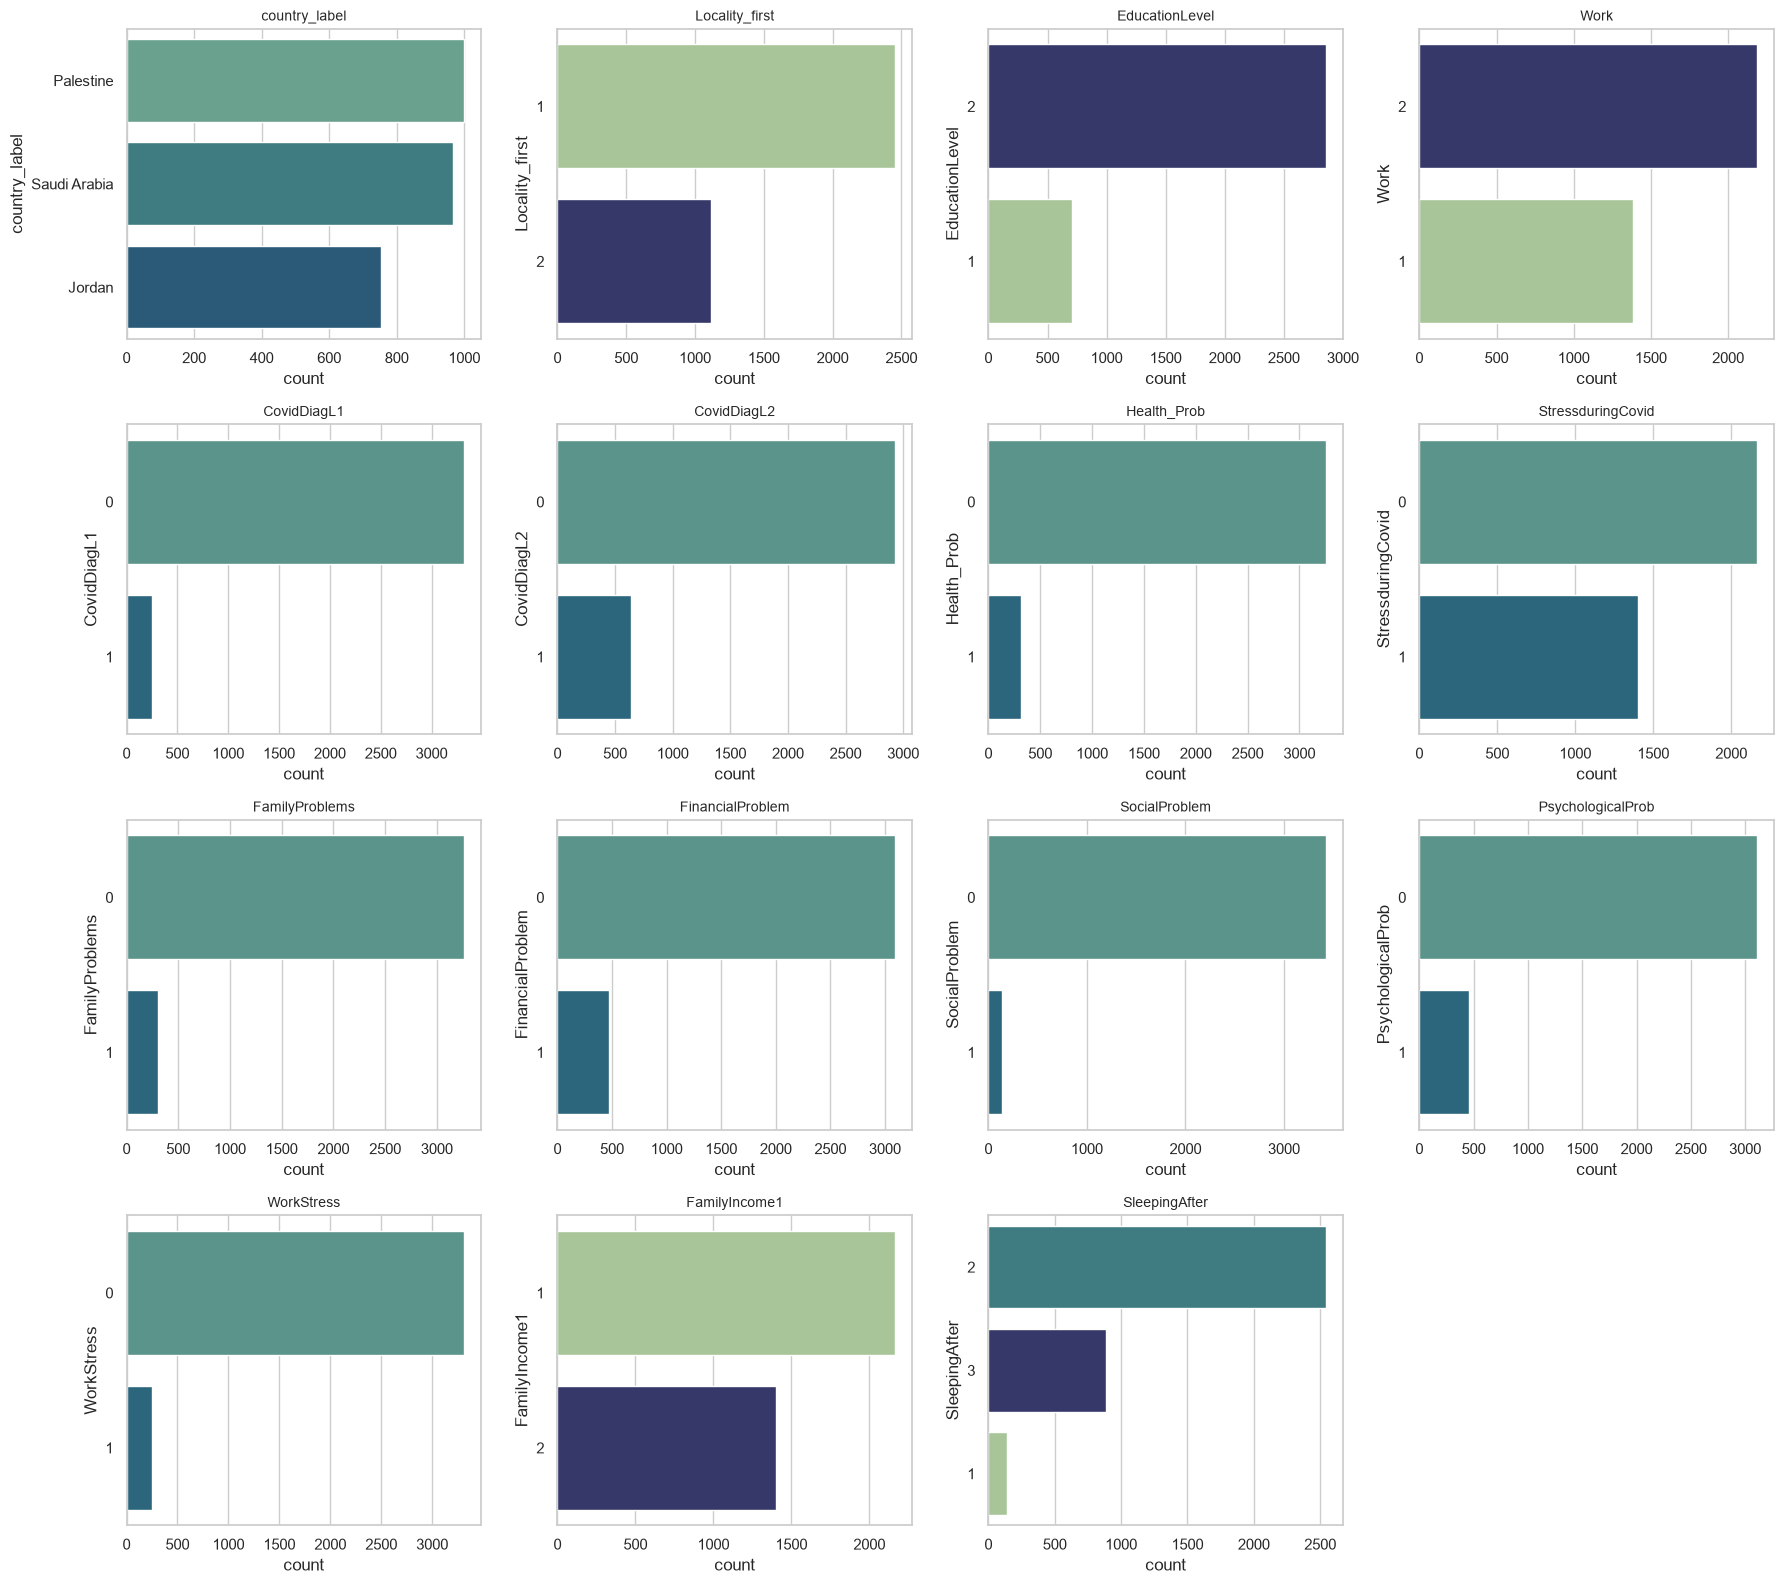

In [11]:
categorical_sdoh = [c for c in sdoh_cols if c not in ["WomenAge", "MariageAge",
                     "NumberofPregnancy", "NumberofAbortions"]]

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for ax, col in zip(axes.flat, categorical_sdoh):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, hue=col, palette="crest", legend=False, ax=ax)
    ax.set_title(col, fontsize=10)
for ax in axes.flat[len(categorical_sdoh):]:
    ax.axis("off")
plt.tight_layout()
save_fig(fig, "sdoh_distributions.png", PROJECT_ROOT, dataset="arab5")
plt.show()

In [12]:
for col in categorical_sdoh:
    ct_dep = pd.crosstab(df[col], df["Depression_Rec1_label"], normalize="index") * 100
    print(f"--- % in each Depression category, by {col} ---")
    print(ct_dep.round(1))
    print()

--- % in each Depression category, by country_label ---
Depression_Rec1_label  Minimal/Mild  Moderate  Moderately Severe/Severe
country_label                                                          
Jordan                         69.6      17.6                      12.7
Palestine                      78.6      11.9                       9.5
Saudi Arabia                   83.5       9.1                       7.4

--- % in each Depression category, by Locality_first ---
Depression_Rec1_label  Minimal/Mild  Moderate  Moderately Severe/Severe
Locality_first                                                         
1                              79.4      11.6                       9.0
2                              80.5      11.5                       8.0

--- % in each Depression category, by EducationLevel ---
Depression_Rec1_label  Minimal/Mild  Moderate  Moderately Severe/Severe
EducationLevel                                                         
1                              75.0 

In [13]:
for col in categorical_sdoh:
    ct_anx = pd.crosstab(df[col], df["Anxeity_Rec_label"], normalize="index") * 100
    print(f"--- % in each Anxiety category, by {col} ---")
    print(ct_anx.round(1))
    print()

--- % in each Anxiety category, by country_label ---
Anxeity_Rec_label  Minimal/Mild  Moderate  Moderately Severe/Severe
country_label                                                      
Jordan                     52.5      33.6                      13.9
Palestine                  70.9      20.7                       8.4
Saudi Arabia               75.1      19.2                       5.7

--- % in each Anxiety category, by Locality_first ---
Anxeity_Rec_label  Minimal/Mild  Moderate  Moderately Severe/Severe
Locality_first                                                     
1                          70.2      22.0                       7.9
2                          69.0      23.5                       7.5

--- % in each Anxiety category, by EducationLevel ---
Anxeity_Rec_label  Minimal/Mild  Moderate  Moderately Severe/Severe
EducationLevel                                                     
1                          63.2      24.2                      12.7
2                    

Saved figure: C:\maternal-mental-health-risk\reports\figures\arab5\phq_gad_correlation_heatmap.png


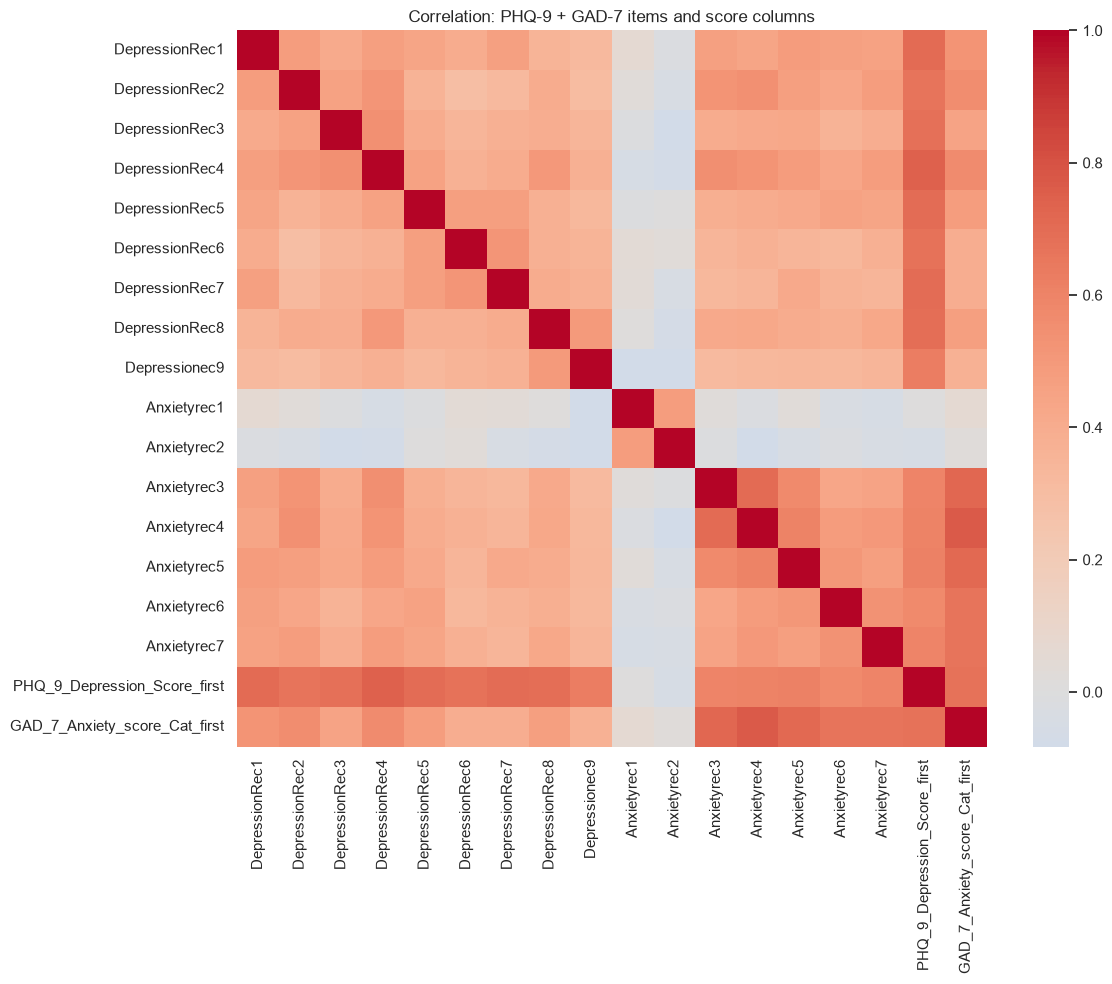

In [14]:
dep_items = [f"DepressionRec{i}" for i in range(1, 9)] + ["Depressionec9"]
anx_items = [f"Anxietyrec{i}" for i in range(1, 8)]
score_cols = ["PHQ_9_Depression_Score_first", "GAD_7_Anxiety_score_Cat_first"]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df[dep_items + anx_items + score_cols].corr(), annot=False, cmap="coolwarm",
            center=0, ax=ax)
ax.set_title("Correlation: PHQ-9 + GAD-7 items and score columns")
plt.tight_layout()
save_fig(fig, "phq_gad_correlation_heatmap.png", PROJECT_ROOT, dataset="arab5")
plt.show()